# Helios Experiment: Data Pipeline So Far

This notebook documents everything done up to now, start to finish:

1. Load the NASA POWER solar data (6 CSV files, 2 months each)
2. Combine them into one dataset
3. Build a proper `timestamp` column
4. Compute hourly PV generation (kWh) from irradiance
5. Generate a synthetic household demand profile (one row per hour of the year)

**Expected folder layout** (run the notebook from the project root):

```
data/raw/solar/Jan-Feb.csv, Mar-Apr.csv, May-Jun.csv, Jul-Aug.csv, Sep-Oct.csv, Nov-Dec.csv
data/processed/
```

In [24]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("data/raw/solar")
PROCESSED_DIR = Path("data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

## 1. The raw data

The solar data came from NASA POWER as **six CSV files**, each covering two months:
`Jan-Feb`, `Mar-Apr`, `May-Jun`, `Jul-Aug`, `Sep-Oct`, `Nov-Dec`.

Each file has a 15-line metadata header before the actual table, so we skip those rows when reading.
Let's peek at one file to confirm the structure.

In [25]:
print(sorted(p.name for p in DATA_DIR.glob("*.csv")))

sample = pd.read_csv(DATA_DIR / "Jan-Feb.csv", skiprows=15)
sample.head()

['Jan-Feb.csv', 'Jul-Aug.csv', 'Mar-Apr.csv', 'May-Jun.csv', 'Nov-Dec.csv', 'Sep-Oct.csv']


,YEAR,MO,DY,HR,ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DNI,PS,WSC
0,2025,1,1,0,0.0,0.0,0.0,100.46,1.69
1,2025,1,1,1,0.0,0.0,0.0,100.40,1.54
2,2025,1,1,2,0.0,0.0,0.0,100.38,1.24
3,2025,1,1,3,0.0,0.0,0.0,100.40,0.83
4,2025,1,1,4,0.0,0.0,0.0,100.44,0.44


## 2. Combining the six files into one

Alphabetical order would put `Jan-Feb` before `Jul-Aug` before `Mar-Apr`, which is wrong chronologically.
So we map each file name to its starting month and sort by that, then concatenate.

In [26]:
from src.data.load_solar import load_solar_data

solar = load_solar_data()
print("\nCombined rows:", len(solar))
solar.head()

First timestamp: 2025-01-01 00:00:00
Last timestamp:  2025-12-31 23:00:00
Rows: 8760
Duplicates: 0
Missing timestamps: 0
Saved: /content/HELIOS/data/processed/solar_combined.csv

Combined rows: 8760


,YEAR,MO,DY,HR,ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DNI,PS,WSC,timestamp,solar_generation_kwh
0,2025,1,1,0,0.0,0.0,0.0,100.46,1.69,2025-01-01 00:00:00,0.0
1,2025,1,1,0,0.0,0.0,0.0,100.46,1.69,2025-01-01 01:00:00,0.0
2,2025,1,1,1,0.0,0.0,0.0,100.40,1.54,2025-01-01 02:00:00,0.0
3,2025,1,1,2,0.0,0.0,0.0,100.38,1.24,2025-01-01 03:00:00,0.0
4,2025,1,1,3,0.0,0.0,0.0,100.40,0.83,2025-01-01 04:00:00,0.0


## 3. Building the `timestamp` column

NASA POWER gives the date as separate `YEAR`, `MO`, `DY`, `HR` columns.
`pd.to_datetime` can assemble these into a single datetime if the columns are named `year`, `month`, `day`, `hour`, so we rename them on the fly.

In [27]:
solar["timestamp"] = pd.to_datetime(
    solar[["YEAR", "MO", "DY", "HR"]].rename(
        columns={"YEAR": "year", "MO": "month", "DY": "day", "HR": "hour"}
    )
)

print("First timestamp:", solar["timestamp"].min())
print("Last timestamp: ", solar["timestamp"].max())
print("Rows:", len(solar))
print("Duplicates:", solar["timestamp"].duplicated().sum())
print("Missing timestamps:", solar["timestamp"].isna().sum())

First timestamp: 2025-01-01 00:00:00
Last timestamp:  2025-12-31 22:00:00
Rows: 8760
Duplicates: 1
Missing timestamps: 0


### Sanity checks

Beyond duplicates and NaNs, two more things are worth confirming:

- **No gaps**: the number of rows should equal the number of hours in the year (8,760).
- **No NASA fill values**: NASA POWER uses `-999` to mark missing readings, and a stray `-999` would turn into huge negative "generation".

In [28]:
expected_hours = len(pd.date_range(solar["timestamp"].min(), solar["timestamp"].max(), freq="h"))
print("Expected hours:", expected_hours, "| Actual rows:", len(solar))

print("Fill values (-999) in irradiance:", (solar["ALLSKY_SFC_SW_DWN"] == -999).sum())
solar["ALLSKY_SFC_SW_DWN"].describe().round(2)

Expected hours: 8759 | Actual rows: 8760
Fill values (-999) in irradiance: 0


,ALLSKY_SFC_SW_DWN
count,8760.00
mean,182.77
std,246.15
min,0.00
25%,0.00
50%,8.44
75%,368.35
max,891.85


## 4. Hourly solar generation

The PV model is intentionally simple. For each hour:

$$
E_{\text{kWh}} = P_{\text{rated}} \times \frac{G}{1000} \times \eta
$$

- `G` is the irradiance in Wh/m² (`ALLSKY_SFC_SW_DWN`). Dividing by 1000 gives the fraction of the 1 kW/m² "standard test" irradiance.
- `P_rated` is the PV array's rated capacity in kW (**5 kW** here).
- `η` is the system efficiency after losses such as wiring, inverter and dust (**0.80** here).

In [29]:
def calculate_solar_generation(irradiance_wh_m2, pv_capacity_kw, system_efficiency):
    """Estimate hourly electricity generated by a PV system (kWh for the hour)."""
    irradiance_factor = irradiance_wh_m2 / 1000
    return pv_capacity_kw * irradiance_factor * system_efficiency


PV_CAPACITY_KW = 5
SYSTEM_EFFICIENCY = 0.80

solar["solar_generation_kwh"] = solar["ALLSKY_SFC_SW_DWN"].apply(
    lambda g: calculate_solar_generation(
        irradiance_wh_m2=g,
        pv_capacity_kw=PV_CAPACITY_KW,
        system_efficiency=SYSTEM_EFFICIENCY,
    )
)

solar[["timestamp", "ALLSKY_SFC_SW_DWN", "solar_generation_kwh"]].head(12)

,timestamp,ALLSKY_SFC_SW_DWN,solar_generation_kwh
0,2025-01-01 00:00:00,0.00,0.00000
1,2025-01-01 00:00:00,0.00,0.00000
2,2025-01-01 01:00:00,0.00,0.00000
3,2025-01-01 02:00:00,0.00,0.00000
4,2025-01-01 03:00:00,0.00,0.00000
5,2025-01-01 04:00:00,0.00,0.00000
6,2025-01-01 05:00:00,0.00,0.00000
7,2025-01-01 06:00:00,94.50,0.37800
8,2025-01-01 07:00:00,275.45,1.10180
9,2025-01-01 08:00:00,476.27,1.90508


Save the combined, processed dataset so later stages can load it directly.

In [30]:
solar.to_csv(PROCESSED_DIR / "solar_combined.csv", index=False)
print("Saved:", PROCESSED_DIR / "solar_combined.csv")

Saved: data/processed/solar_combined.csv


### Looking at the solar data

Two quick views: the average generation by hour of day (the classic bell curve), and the monthly total, which should show the dry-season peaks and rainy-season dips.

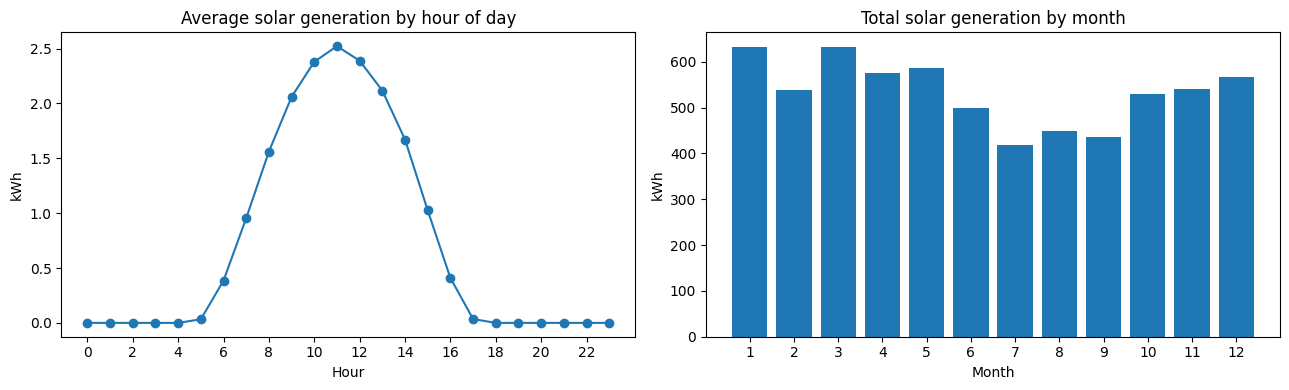

Total annual generation: 6404 kWh


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

hourly_avg = solar.groupby(solar["timestamp"].dt.hour)["solar_generation_kwh"].mean()
axes[0].plot(hourly_avg.index, hourly_avg.values, marker="o")
axes[0].set_title("Average solar generation by hour of day")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("kWh")
axes[0].set_xticks(range(0, 24, 2))

monthly = solar.groupby(solar["timestamp"].dt.month)["solar_generation_kwh"].sum()
axes[1].bar(monthly.index, monthly.values)
axes[1].set_title("Total solar generation by month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("kWh")
axes[1].set_xticks(range(1, 13))

plt.tight_layout()
plt.show()

print(f"Total annual generation: {solar['solar_generation_kwh'].sum():.0f} kWh")

## 5. Household demand profile

There's no real meter data for this project, so demand is **synthetic**, built bottom-up for a modest urban Nigerian household.

How it works:

1. Two representative 24-hour profiles (weekday and weekend), each with morning and evening peaks.
2. Every hour of the year is assigned the matching profile based on its day of week.
3. **Multiplicative Gaussian noise** (default 6%) adds natural hour-to-hour variation.
4. **Random spikes** (3% chance per daytime hour, +0.20 to +0.45 kWh) mimic things like water pumping or ironing.
5. A **floor** of 0.05 kWh keeps the fridge and router running at all times.

A fixed `seed` makes it reproducible.

In [ ]:
def generate_household_demand(
    year: int = 2025,
    noise_std: float = 0.06,
    base_load_min: float = 0.05,
    seed: int = 42,
) -> pd.DataFrame:
    """Generate an hourly residential electricity demand profile (kWh)
    based on a bottom-up appliance model for a modest urban Nigerian household."""
    rng = np.random.default_rng(seed)

    # 1. Base 24-hour weekday profile
    weekday_base = np.array([
        0.14, 0.14, 0.08, 0.08, 0.08, 0.14,                      # 00-05 night base
        0.75, 0.85, 0.35, 0.22,                                  # 06-09 morning peak
        0.20, 0.19, 0.19, 0.19, 0.25, 0.25, 0.25,                # 10-16 midday plateau
        0.30, 0.45, 0.60, 0.50, 0.45, 0.30, 0.14,                # 17-23 evening peak
    ])

    # 2. Base 24-hour weekend profile (people home, later morning peak)
    weekend_base = np.array([
        0.14, 0.14, 0.08, 0.08, 0.08, 0.10,                      # 00-05 slower wake-up
        0.25, 0.60, 0.80, 0.50,                                  # 06-09 delayed morning peak
        0.45, 0.40, 0.42, 0.40, 0.45, 0.45, 0.40,                # 10-16 occupants home
        0.40, 0.55, 0.65, 0.60, 0.50, 0.35, 0.20,                # 17-23 extended evening
    ])

    # 3. Full hourly timestamp range
    timestamps = pd.date_range(
        start=f"{year}-01-01 00:00:00",
        end=f"{year}-12-31 23:00:00",
        freq="h",
    )

    df = pd.DataFrame({"timestamp": timestamps})
    df["hour"] = df["timestamp"].dt.hour
    df["day_of_week"] = df["timestamp"].dt.dayofweek  # Monday=0, Sunday=6
    df["is_weekend"] = df["day_of_week"] >= 5

    # 4. Pick weekday/weekend profile for each hour
    base_demand = np.where(
        df["is_weekend"],
        weekend_base[df["hour"]],
        weekday_base[df["hour"]],
        )

    # 5. Stochastic variation
    noise = rng.normal(loc=1.0, scale=noise_std, size=len(df))
    stochastic_demand = base_demand * noise

    # Occasional short high-power spikes during active hours (07:00-21:00)
    daytime_mask = (df["hour"] >= 7) & (df["hour"] <= 21)
    random_events = (
        (rng.random(len(df)) < 0.03) & daytime_mask
    ) * rng.uniform(0.20, 0.45, len(df))

    total_demand = stochastic_demand + random_events

    # 6. Floor for continuous loads (refrigerator / standby)
    df["demand_kwh"] = np.maximum(total_demand, base_load_min).round(3)

    return df[["timestamp", "hour", "day_of_week", "is_weekend", "demand_kwh"]]

In [ ]:
solar_year = int(solar["timestamp"].dt.year.iloc[0])
demand = generate_household_demand(year=solar_year)

demand.to_csv(PROCESSED_DIR / "household_demand.csv", index=False)
print("Saved:", PROCESSED_DIR / "household_demand.csv")

print("Profile shape:", demand.shape)
demand.head(24)

In [ ]:
print("Summary statistics (kWh):")
print(demand["demand_kwh"].describe().round(3))

daily_totals = demand.resample("D", on="timestamp")["demand_kwh"].sum()
print(f"\nAverage daily demand: {daily_totals.mean():.2f} kWh/day")
print(f"Weekday mean: {daily_totals[daily_totals.index.dayofweek < 5].mean():.2f} kWh/day")
print(f"Weekend mean: {daily_totals[daily_totals.index.dayofweek >= 5].mean():.2f} kWh/day")
print("\nAnnual demand:", demand["demand_kwh"].sum().round(2), "kWh")
print("Maximum hourly demand:", demand["demand_kwh"].max(), "kWh")

In [ ]:
first_day = demand.head(24)

plt.figure(figsize=(8, 4))
plt.plot(first_day["hour"], first_day["demand_kwh"], marker="o")
plt.xlabel("Hour")
plt.ylabel("Demand (kWh)")
plt.title("Synthetic Household Demand — First Day")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.show()

Weekday vs weekend shape, averaged over the whole year:

In [ ]:
profile = demand.groupby(["is_weekend", "hour"])["demand_kwh"].mean().unstack(0)
profile.columns = ["Weekday", "Weekend"]

profile.plot(figsize=(8, 4), marker="o")
plt.xlabel("Hour")
plt.ylabel("Mean demand (kWh)")
plt.title("Average demand profile: weekday vs weekend")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.show()

## 6. Grid availability (synthetic outage model)

Outages are modelled as **events**, not independent hourly coin flips. Each event has a start hour and a duration, and the grid is OFF for that whole span. If events overlap, they merge into one longer outage.

The assumptions are set here, before any strategy is run, and are not tuned to favour HELIOS. The naive strategy and HELIOS will both be run against this same `grid` column.

These numbers are **scenario assumptions**, not measured Uyo data. I run three scenarios (mild, moderate, severe) so the conclusions don't rest on one guess.

In [ ]:
def generate_grid_availability(
    timestamps,
    events_per_year=120,
    mean_duration_h=3.0,
    duration_sigma=0.6,
    max_duration_h=24,
    start_hour_weights=None,   # optional length-24 array, e.g. more outages in the evening
    seed=7,
):
    """Return a DataFrame with 'timestamp' and 'grid' (1 = available, 0 = outage)."""
    rng = np.random.default_rng(seed)
    n = len(timestamps)
    hours = pd.DatetimeIndex(timestamps).hour

    # Number of events: Poisson around the yearly average
    n_events = rng.poisson(events_per_year)

    # Start positions: uniform, or weighted by hour of day
    if start_hour_weights is None:
        p = None
    else:
        w = np.asarray(start_hour_weights, dtype=float)[hours]
        p = w / w.sum()
    starts = rng.choice(n, size=n_events, p=p)

    # Durations: lognormal (mostly short, occasionally long), at least 1 h
    mu = np.log(mean_duration_h) - duration_sigma**2 / 2   # keeps the mean ≈ mean_duration_h
    durations = rng.lognormal(mu, duration_sigma, size=n_events)
    durations = np.clip(np.ceil(durations), 1, max_duration_h).astype(int)

    grid = np.ones(n, dtype=int)
    for s, d in zip(starts, durations):
        grid[s : s + d] = 0

    return pd.DataFrame({"timestamp": timestamps, "grid": grid})


SCENARIOS = {
    "mild":     dict(events_per_year=60,  mean_duration_h=2.0),
    "moderate": dict(events_per_year=120, mean_duration_h=3.0),
    "severe":   dict(events_per_year=240, mean_duration_h=4.0),
    "extreme":  dict(events_per_year=700, mean_duration_h=4.0),
}

grid_scenarios = {
    name: generate_grid_availability(demand["timestamp"], **params)
    for name, params in SCENARIOS.items()
}
grid_df = grid_scenarios["moderate"]

grid_availability = pd.DataFrame({"timestamp": demand["timestamp"]})
for name, g in grid_scenarios.items():
    grid_availability[f"grid_{name}"] = g["grid"].values

grid_availability.to_csv(PROCESSED_DIR / "grid_availability.csv", index=False)
print("Saved:", PROCESSED_DIR / "grid_availability.csv")

In [ ]:
def outage_summary(g):
    off = g["grid"] == 0
    episode = (off & ~off.shift(fill_value=False)).cumsum()
    lengths = off.groupby(episode[off]).sum()
    return {
        "availability_%": round(100 * g["grid"].mean(), 1),
        "outage_hours": int(off.sum()),
        "episodes": len(lengths),
        "mean_len_h": round(lengths.mean(), 2),
        "longest_h": int(lengths.max()),
    }

print(pd.DataFrame({k: outage_summary(v) for k, v in grid_scenarios.items()}).T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
two_weeks = grid_df.head(24 * 14)
axes[0].step(two_weeks["timestamp"], two_weeks["grid"], where="post")
axes[0].set_title("Grid status, first 14 days (moderate)")
axes[0].set_yticks([0, 1], ["OFF", "ON"])
axes[0].tick_params(axis="x", rotation=30)

off = grid_df["grid"] == 0
episode = (off & ~off.shift(fill_value=False)).cumsum()
axes[1].hist(off.groupby(episode[off]).sum(), bins=range(1, 26), edgecolor="white")
axes[1].set_title("Outage duration distribution (moderate)")
axes[1].set_xlabel("Hours")
plt.tight_layout()
plt.show()

## 7. Merging into one state table

All inputs are now hourly series for the same year. We merge them into a single table, where **one row is one hour of the simulated household's year**. The merge checks that no hours were lost, then freezes the result as `state_table.csv`, the input to the simulation engine.

`irradiance_wh_m2` is kept alongside `solar_generation_kwh` so PV size can be varied later without going back to the raw files.

In [ ]:
GRID_COLS = ["grid_mild", "grid_moderate", "grid_severe", "grid_extreme"]

solar_part = solar[["timestamp", "ALLSKY_SFC_SW_DWN", "solar_generation_kwh"]].rename(
    columns={"ALLSKY_SFC_SW_DWN": "irradiance_wh_m2"}
)

state = (
    demand.merge(solar_part, on="timestamp", how="inner", validate="one_to_one")
    .merge(grid_availability, on="timestamp", how="inner", validate="one_to_one")
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# An inner merge silently drops unmatched hours, so verify nothing was lost
assert len(state) == len(solar) == len(demand) == len(grid_availability), (
    f"Row mismatch: solar={len(solar)}, demand={len(demand)}, "
    f"grid={len(grid_availability)}, merged={len(state)}"
)
assert state.isna().sum().sum() == 0, "NaNs in merged table"
assert (state["solar_generation_kwh"] >= 0).all(), "negative solar generation"
assert (state["demand_kwh"] > 0).all(), "non-positive demand"
for col in GRID_COLS:
    assert state[col].isin([0, 1]).all(), f"{col} must be 0/1"

state = state[
    ["timestamp", "hour", "day_of_week", "is_weekend",
     "irradiance_wh_m2", "solar_generation_kwh", "demand_kwh", *GRID_COLS]
]
state.to_csv(PROCESSED_DIR / "state_table.csv", index=False)
print("Saved:", PROCESSED_DIR / "state_table.csv", "| rows:", len(state))
state.head(8)

In [ ]:
print(pd.DataFrame(
    {c: outage_summary(state.rename(columns={c: "grid"})) for c in GRID_COLS}
).T)
print(f"\nAnnual solar:  {state['solar_generation_kwh'].sum():.0f} kWh")
print(f"Annual demand: {state['demand_kwh'].sum():.0f} kWh")

fig, axes = plt.subplots(len(GRID_COLS), 1, figsize=(11, 5), sharex=True)
first_two_weeks = state.head(24 * 14)
for ax, col in zip(axes, GRID_COLS):
    ax.step(first_two_weeks["timestamp"], first_two_weeks[col], where="post")
    ax.set_ylabel(col.replace("grid_", ""))
    ax.set_yticks([0, 1])
plt.suptitle("Grid status by scenario, first 14 days")
plt.tight_layout()
plt.show()

## 8. Where things stand

| Dataset | Source | Rows | Key columns |
|---|---|---|---|
| `solar` | NASA POWER (real) | one per hour of the solar year | `timestamp`, `ALLSKY_SFC_SW_DWN`, `solar_generation_kwh` |
| `demand` | Synthetic bottom-up model | 8,784 | `timestamp`, `hour`, `day_of_week`, `is_weekend`, `demand_kwh` |
| `grid` | Synthetic event-based model | 8,784 | `timestamp`, `grid_mild`, `grid_moderate`, `grid_severe`, `grid_extreme` |
| `state` | Merged solar + demand + grid | one per hour of the year | all columns above, saved as `state_table.csv` |


### Next steps

- Build the simulation engine with the per-hour energy-balance check
- Build the baseline (naive) battery dispatch strategy
- Build the HELIOS predictive dispatch strategy